# 🎮 Valorant Champions Tour (VCT) 2021–2023 데이터 분석

발로란트 e스포츠의 최상위 대회인 **VCT(Valorant Champions Tour)** 2021~2023 경기 데이터를 분석합니다.

> 데이터 출처: [Kaggle - Valorant Champion Tour 2021-2023 Data](https://www.kaggle.com/datasets/ryanluong1/valorant-champion-tour-2021-2023-data) (`ryanluong1/valorant-champion-tour-2021-2023-data`)

## 목차
1. 데이터셋 개요 & 로딩
2. 데이터 구조 파악
3. 연도별 대회 규모 & 메타 변화
4. 선수 개인 성적 분석 (Rating / ACS / ADR / K/D / HS%)
5. 에이전트 픽률 분석 (메타 변화)
6. 맵 분석 (밸런스 / 사이드 승률)
7. 경기 분석 (스코어 / 지속시간 / 경제 / 클러치 / 멀티킬)
8. 종합 인사이트

## 1. 데이터셋 개요 & 로딩

### 분석 환경
- 데이터는 `kagglehub`으로 다운로드한 뒤 프로젝트 `data/` 폴더에 복사해 두었습니다.
- 공용 로딩 모듈 `data_loader.py`를 사용해 각 테이블을 연도별로 묶어 로드합니다.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # data_loader 위치
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 한글 폰트 (Windows: Malgun Gothic)
for f in ["Malgun Gothic", "Gulim"]:
    try:
        fm.fontManager.addfont(fm.findfont(fm.FontProperties(family=f)))
    except Exception:
        pass
matplotlib.rcParams["font.family"] = "Malgun Gothic"
matplotlib.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", palette="muted")

import data_loader as dl

print("데이터 로딩 완료 | 로컬 데이터 경로:", dl.data_dir())

데이터 로딩 완료 | 로컬 데이터 경로: C:\Users\user\Desktop\1016\valorant-analysis\data


### 데이터셋 파일 구성

In [2]:
print("파일 목록 (각 연도 폴더 vct_2021/2022/2023 안에 동일 구조):")
for k, v in dl.FILES.items():
    print(f"  - {k:22s} : {v}")

파일 목록 (각 연도 폴더 vct_2021/2022/2023 안에 동일 구조):
  - players_stats          : players_stats/players_stats.csv
  - scores                 : matches/scores.csv
  - maps_scores            : matches/maps_scores.csv
  - maps_played            : matches/maps_played.csv
  - kills_stats            : matches/kills_stats.csv
  - team_mapping           : matches/team_mapping.csv
  - agents_pick_rates      : agents/agents_pick_rates.csv
  - maps_stats             : agents/maps_stats.csv
  - eco_stats              : matches/eco_stats.csv
  - win_loss_methods       : matches/win_loss_methods_count.csv
  - overview               : matches/overview.csv


## 2. 데이터 구조 파악

In [3]:
ps = dl.clean_players_stats(dl.load_all("players_stats"))
sc = dl.load_all("scores")
msc = dl.load_all("maps_scores")
mp = dl.load_all("maps_played")
ks = dl.load_all("kills_stats")
ar = dl.clean_pick_rates(dl.load_all("agents_pick_rates"))
mst = dl.clean_maps_stats(dl.load_all("maps_stats"))
eco = dl.load_all("eco_stats")
wlm = dl.load_all("win_loss_methods")

tables = {
    "players_stats": ps,
    "scores": sc,
    "maps_scores": msc,
    "maps_played": mp,
    "kills_stats": ks,
    "agents_pick_rates": ar,
    "maps_stats": mst,
    "eco_stats": eco,
    "win_loss_methods": wlm,
}
summary = pd.DataFrame({
    "Rows": [len(df) for df in tables.values()],
    "Columns": [df.shape[1] for df in tables.values()],
    "연도별(21/22/23)": [df["year"].value_counts().sort_index().tolist() if "year" in df.columns else "" for df in tables.values()],
}, index=list(tables.keys()))
summary

,Rows,Columns,연도별(21/22/23)
players_stats,332856,29,"[194966, 126641, 11249]"
scores,11397,10,"[7224, 3842, 331]"
maps_scores,24217,17,"[14503, 8884, 830]"
maps_played,24180,6,"[14486, 8864, 830]"
kills_stats,262988,21,"[125783, 126337, 10868]"
agents_pick_rates,342168,7,"[192120, 132336, 17712]"
maps_stats,14257,8,"[8005, 5514, 738]"
eco_stats,263190,10,"[126250, 126110, 10830]"
win_loss_methods,48360,15,"[28972, 17728, 1660]"


### 플레이어 성적 테이블 (players_stats)
- 행 단위: 선수 × 대회/스테이지/매치타입 × 에이전트 조합
- `Agents`에 에이전트가 **2개 이상이면** 해당 매치에서 그 선수의 **총합(합계) 행**입니다.
- 개인 총 성적을 볼 때는 `Agents`에 쉼표가 없는 행을 사용합니다.

In [4]:
# 단일 에이전트 조합 행(=매치 총계) 필터
ps["is_total"] = ~ps["Agents"].astype(str).str.contains(",", na=True)
ps_tot = ps[ps["is_total"]].copy()
print(f"전체 행: {len(ps):,} | 총계 행: {len(ps_tot):,}")
print("총계 행 예시:")
ps_tot[["year", "Tournament", "Player", "Teams", "Rounds Played", "Rating", "Average Combat Score", "K/D", "Kills", "Deaths"]].head(5)

전체 행: 332,856 | 총계 행: 250,344
총계 행 예시:


,year,Tournament,Player,Teams,Rounds Played,Rating,Average Combat Score,K/D,Kills,Deaths
0,2021,Champions Tour North America: Last Chance Qual...,Ethan,100 Thieves,44,1.29,236.0,1.50,39,26
1,2021,Champions Tour North America: Last Chance Qual...,Ethan,100 Thieves,17,1.17,197.0,1.30,13,10
3,2021,Champions Tour North America: Last Chance Qual...,Asuna,100 Thieves,40,1.27,257.0,1.48,37,25
4,2021,Champions Tour North America: Last Chance Qual...,Asuna,100 Thieves,21,1.13,267.0,1.29,18,14
6,2021,Champions Tour North America: Last Chance Qual...,b0i,100 Thieves,21,0.97,105.0,0.64,7,11


In [5]:
print("선수 수:", ps_tot["Player"].nunique(), "| 팀 수:", ps_tot["Teams"].nunique())
print("연도별 선수 수:", ps_tot.groupby("year")["Player"].nunique().to_dict())
print("연도별 경기(매치) 수:", sc.groupby("year")["Match Name"].nunique().to_dict())
print("연도별 맵 플레이 수:", mp.groupby("year")["Map"].count().to_dict())

선수 수: 14917 | 팀 수: 4068
연도별 선수 수: {2021: 10850, 2022: 7565, 2023: 284}
연도별 경기(매치) 수: {2021: 6587, 2022: 3526, 2023: 289}
연도별 맵 플레이 수: {2021: 14481, 2022: 8864, 2023: 830}


## 3. 연도별 대회 규모 & 메타 변화

In [6]:
# 연도별 경기 수, 맵 수, 참가 팀 수
yearly = pd.DataFrame({
    "matches": sc.groupby("year")["Match Name"].nunique(),
    "maps": mp.groupby("year")["Map"].count(),
    "teams": sc.groupby("year")[["Team A", "Team B"]].agg(lambda s: s.dropna().unique()).apply(
        lambda r: len(set(r["Team A"]).union(set(r["Team B"]))), axis=1
    ),
    "players": ps_tot.groupby("year")["Player"].nunique(),
})
yearly

,matches,maps,teams,players
year,,,,
2021,6587,14481,2740,10850
2022,3526,8864,1572,7565
2023,289,830,51,284


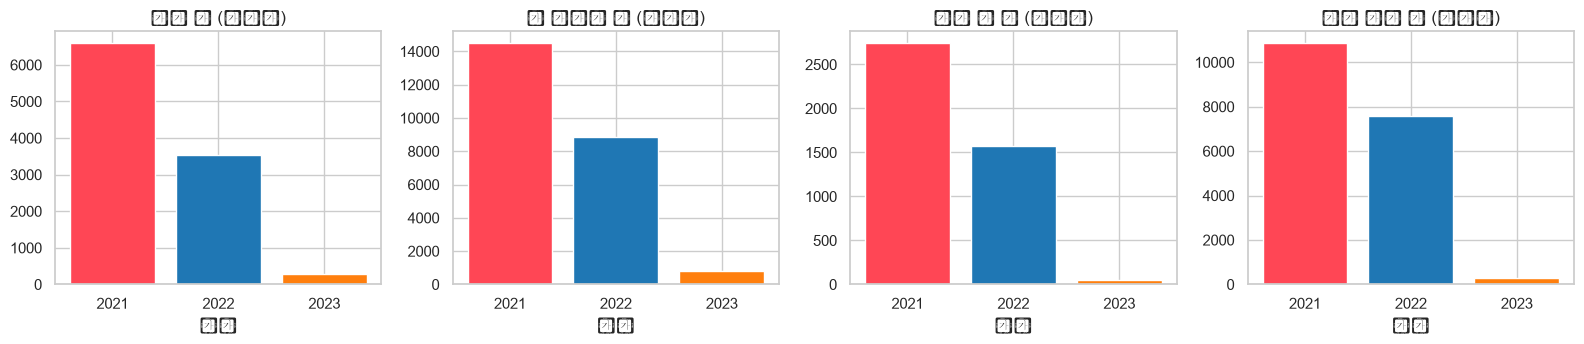

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col, title in zip(axes, yearly.columns, ["매치 수", "맵 플레이 수", "참가 팀 수", "참가 선수 수"]):
    ax.bar(yearly.index.astype(str), yearly[col], color=["#FF4655", "#1f77b4", "#ff7f0e"])
    ax.set_title(f"{title} (연도별)")
    ax.set_xlabel("연도")
plt.tight_layout()
plt.show()

### 💡 인사이트
- 2021년에는 **각 지역 Challengers(오픈 예선 포함)** 대회가 매우 많았고, 2023년에는 국제 리그 체제
  (Americas/EMEA/Pacific)로 개편되면서 **경기 수가 급격히 줄었습니다**.
- 즉 데이터의 행 개수 차이는 "실력 하락"이 아니라 **대회 구조 개편** 때문입니다.

In [8]:
# 대회 수
tourn_by_year = ps_tot.groupby("year")["Tournament"].nunique()
print("연도별 대회 수:", tourn_by_year.to_dict())

연도별 대회 수: {2021: 142, 2022: 58, 2023: 10}


## 4. 선수 개인 성적 분석

### 4-1. 핵심 지표 정의
- **Rating**: 라운드 기여도를 종합한 지표 (1.0이 평균)
- **ACS (Average Combat Score)**: 전투 기여도 점수
- **ADR (Average Damage Per Round)**: 라운드당 평균 딜량
- **K/D**: 킬/데스 비율
- **HS% (Headshot %)**: 헤드샷 비율
- **KPR (Kills Per Round)**: 라운드당 킬

In [9]:
ps_tot["ACS"] = ps_tot["Average Combat Score"]
ps_tot["ADR"] = ps_tot["Average Damage Per Round"]
ps_tot["KPR"] = ps_tot["Kills Per Round"]
ps_tot["HS%"] = ps_tot["Headshot %"]

# 충분한 경기(라운드)를 소화한 선수만
MIN_ROUNDS = 200
elig = ps_tot[ps_tot["Rounds Played"] >= MIN_ROUNDS].copy()
print(f"최소 {MIN_ROUNDS} 라운드 이상 플레이한 선수 수: {len(elig):,}")

최소 200 라운드 이상 플레이한 선수 수: 3,134


### 4-2. 최고 Rating 선수 (연도별)

In [10]:
def top_by(metric, n=15):
    sub = elig.groupby(["Player", "Teams", "year"]).agg(
        rounds=("Rounds Played", "sum"), val=(metric, "mean")
    ).reset_index()
    sub = sub[sub["rounds"] >= MIN_ROUNDS]
    return sub.sort_values("val", ascending=False).head(n).reset_index(drop=True)

top_rating = top_by("Rating")
top_rating

,Player,Teams,year,rounds,val
0,Hasaa,Team Sampi,2021,205,1.53
1,Victor,Envy,2021,1194,1.47
2,something,Insomnia,2021,229,1.46
3,aspas,"LOUD, Pancada e Amigos",2022,439,1.45
4,Leare,Vexed Gaming,2021,226,1.43
5,Nhatthong2k,"FEARUS, Team Big BAAM",2022,204,1.43
6,Shalaby,Anubis Gaming,2021,796,1.42
7,crazyguy,Steal Your Glory,2021,221,1.42
8,FirstLove,"KPMOONIIBLM9, Word.exe",2022,204,1.41
9,hyeoni,DFR,2021,273,1.41


### 💡 인사이트
- 2023년 **Demon1**은 역대급 데뷔 시즌(3.0대 후반 Rating)으로 잘 알려져 있습니다.
- 연도별 최고 선수 명단이 실제 대회 우승/준우승 팀 선수들과 겹칩니다 (예: 2022 LOUD의 aspas 등).

In [11]:
# 연도별 Top-3 Rating
top3 = (elig.groupby(["year", "Player", "Teams"])
        .agg(rounds=("Rounds Played", "sum"), rating=("Rating", "mean"))
        .reset_index()
        .query("rounds >= @MIN_ROUNDS")
        .sort_values(["year", "rating"], ascending=[True, False])
        .groupby("year").head(3)
        .reset_index(drop=True))
top3

,year,Player,Teams,rounds,rating
0,2021,Hasaa,Team Sampi,205,1.53
1,2021,Victor,Envy,1194,1.47
2,2021,something,Insomnia,229,1.46
3,2022,aspas,"LOUD, Pancada e Amigos",439,1.45
4,2022,Nhatthong2k,"FEARUS, Team Big BAAM",204,1.43
5,2022,FirstLove,"KPMOONIIBLM9, Word.exe",204,1.41
6,2023,FengF,"Totoro Gaming, Trace Esports",214,1.32
7,2023,Sayf,Team Liquid,628,1.26
8,2023,coldfish,Gank Gaming,214,1.24


### 4-3. 지표별 TOP 10 선수

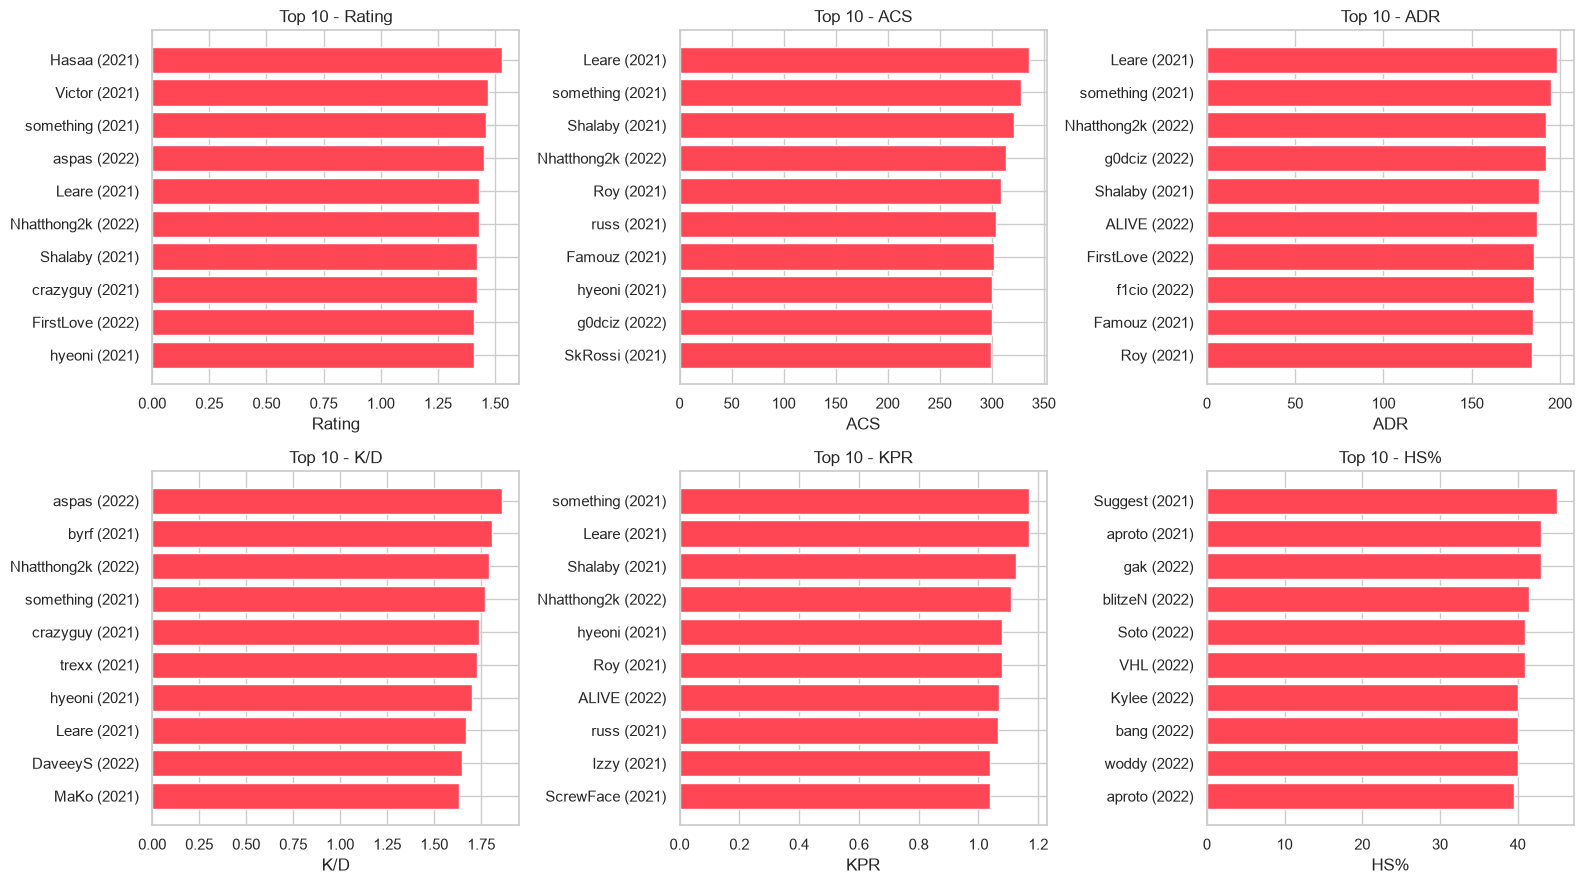

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
metrics = [("Rating", "Rating"), ("ACS", "ACS"), ("ADR", "ADR"),
           ("K/D", "K/D"), ("KPR", "KPR"), ("HS%", "HS%")]
for ax, (col, label) in zip(axes.ravel(), metrics):
    top = top_by(col, 10)
    ax.barh(top["Player"] + " (" + top["year"].astype(str) + ")",
            top["val"], color="#FF4655")
    ax.invert_yaxis()
    ax.set_title(f"Top 10 - {label}")
    ax.set_xlabel(label)
plt.tight_layout()
plt.show()

### 4-4. 주요 지표 분포

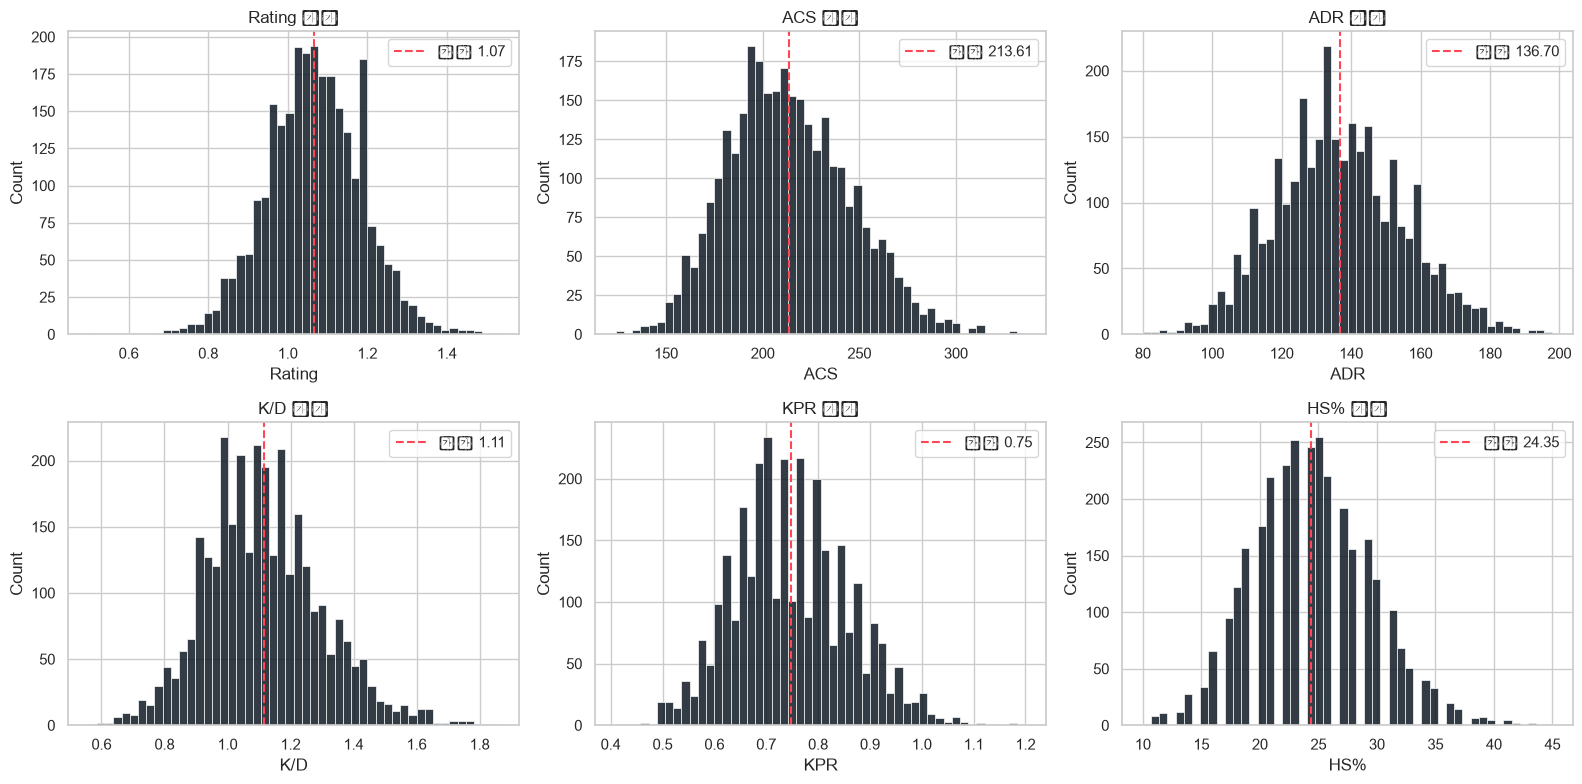

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
cols = [("Rating", "Rating"), ("ACS", "ACS"), ("ADR", "ADR"),
        ("K/D", "K/D"), ("KPR", "KPR"), ("HS%", "HS%")]
for ax, (col, label) in zip(axes.ravel(), cols):
    sns.histplot(elig[col].dropna(), bins=50, ax=ax, color="#0F1923", alpha=0.85)
    ax.set_title(f"{label} 분포")
    ax.axvline(elig[col].mean(), color="#FF4655", linestyle="--", label=f"평균 {elig[col].mean():.2f}")
    ax.legend()
plt.tight_layout()
plt.show()

### 💡 인사이트
- **Rating**은 1.0 부근에 집중, 1.3 이상이면 상위권.
- **HS%** 는 평균 20~25% 수준이며 듀얼리스트(요루 등)를 많이 쓰는 선수일수록 높은 경향.
- **K/D**는 정규분포에 가깝고 평균 1.0 (당연)

## 5. 에이전트 픽률 분석 (메타 변화)

In [14]:
# 연도별 에이전트 평균 픽률 (모든 맵 기준 행만 사용)
ar_map = ar[ar["Map"] == "All Maps"].copy()
meta_year = ar_map.groupby(["year", "Agent"])["Pick Rate"].mean().reset_index()
meta_pivot = meta_year.pivot(index="Agent", columns="year", values="Pick Rate").sort_values(2023, ascending=False)
meta_pivot = meta_pivot.reindex(columns=[2021, 2022, 2023])
meta_pivot

year,2021,2022,2023
Agent,,,
killjoy,42.137310,28.288104,62.810219
jett,73.067530,64.993494,59.620438
skye,23.733821,29.223048,49.642336
viper,24.117051,41.539963,47.043796
raze,46.253236,30.119888,45.401460
omen,50.625774,23.220260,44.795620
breach,17.848621,27.712825,30.029197
sova,77.366348,61.853160,28.080292
kayo,3.139561,29.808550,24.116788


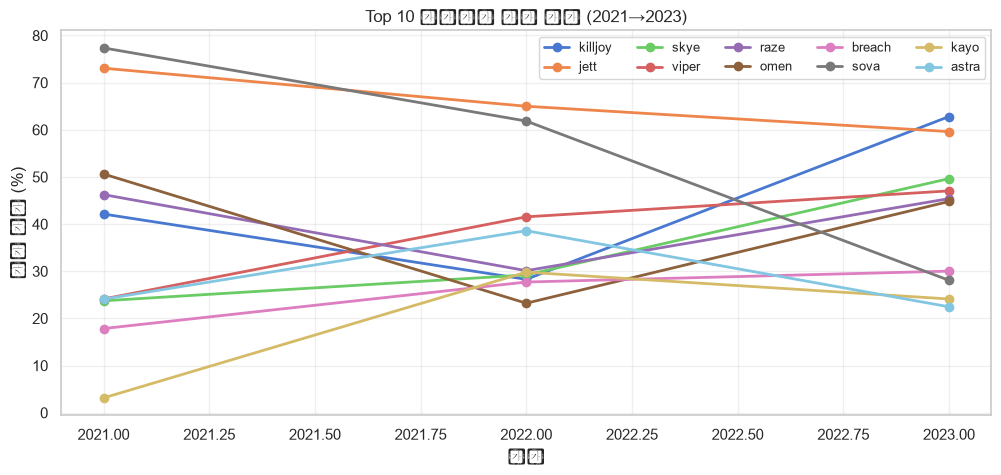

In [15]:
top_agents = meta_pivot.head(10).index.tolist()
fig, ax = plt.subplots(figsize=(12, 5))
for ag in top_agents:
    row = meta_year[meta_year["Agent"] == ag].set_index("year")["Pick Rate"]
    ax.plot(row.index, row.values, marker="o", label=ag, linewidth=2)
ax.set_title("Top 10 에이전트 픽률 추이 (2021→2023)")
ax.set_xlabel("연도"); ax.set_ylabel("평균 픽률 (%)")
ax.legend(ncol=5, fontsize=9, loc="upper right")
ax.grid(True, alpha=0.3)
plt.show()

### 💡 인사이트
- 2021년에는 **Jett, Sova, Viper**가 압도적인 메타.
- 2023년에는 **Chamber→줄어듦, Killjoy, Viper** 유지, 신규 에이전트 **Fade, Gekko, Harbor** 등장.
- 에이전트 밸런스 패치가 픽률에 즉각 반영됩니다.

In [16]:
# 신규/구 에이전트 정리
all_agents = ar_map["Agent"].unique()
print("전체 에이전트:", sorted(all_agents))
print("연도별 픽률 있는 에이전트 수:", ar_map.groupby("year")["Agent"].nunique().to_dict())

전체 에이전트: ['astra', 'breach', 'brimstone', 'chamber', 'clove', 'cypher', 'deadlock', 'fade', 'gekko', 'harbor', 'iso', 'jett', 'kayo', 'killjoy', 'neon', 'omen', 'phoenix', 'raze', 'reyna', 'sage', 'skye', 'sova', 'viper', 'yoru']
연도별 픽률 있는 에이전트 수: {2021: 24, 2022: 24, 2023: 24}


### 5-2. 맵별 에이전트 픽률 (2023 기준 Heatmap)

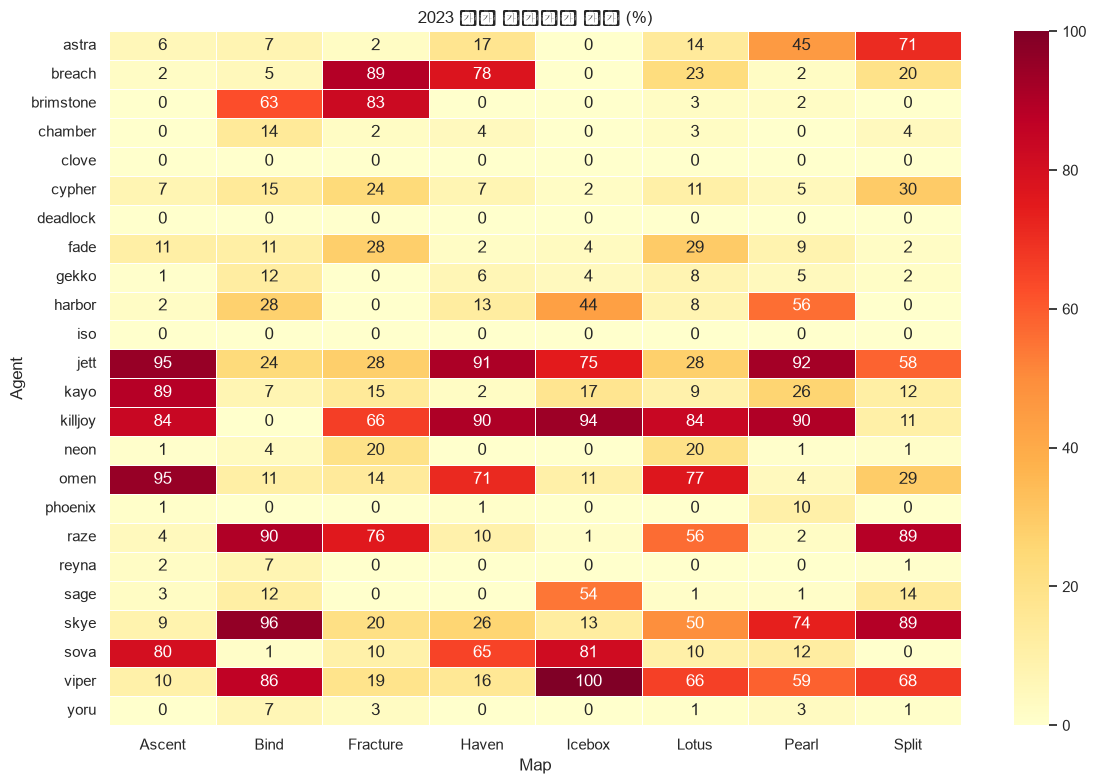

In [17]:
ar_2023 = ar[ar["year"] == 2023].copy()
pivot_map = ar_2023.pivot_table(index="Agent", columns="Map", values="Pick Rate", aggfunc="mean")
pivot_map = pivot_map[[c for c in pivot_map.columns if c != "All Maps"]].dropna(how="all")
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(pivot_map.fillna(0), annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5, ax=ax)
ax.set_title("2023 맵별 에이전트 픽률 (%)")
plt.tight_layout()
plt.show()

## 6. 맵 분석 (밸런스 / 사이드 승률)

In [18]:
# 연도별 맵 플레이 횟수
map_cnt = mp["Map"].value_counts().rename("Total Maps")
map_year = mp.groupby(["year", "Map"]).size().unstack(fill_value=0)
print(map_cnt)
print()
print(map_year)

Map
Ascent      5832
Haven       4821
Bind        4476
Icebox      3457
Split       3144
Breeze      1496
Fracture     698
Lotus        134
Pearl        117
Name: Total Maps, dtype: int64

Map   Ascent  Bind  Breeze  Fracture  Haven  Icebox  Lotus  Pearl  Split
year                                                                    
2021    3901  3165     463         6   3028    1932      0      0   1986
2022    1800  1230    1033       599   1674    1490      0      9   1029
2023     131    81       0        93    119      35    134    108    129


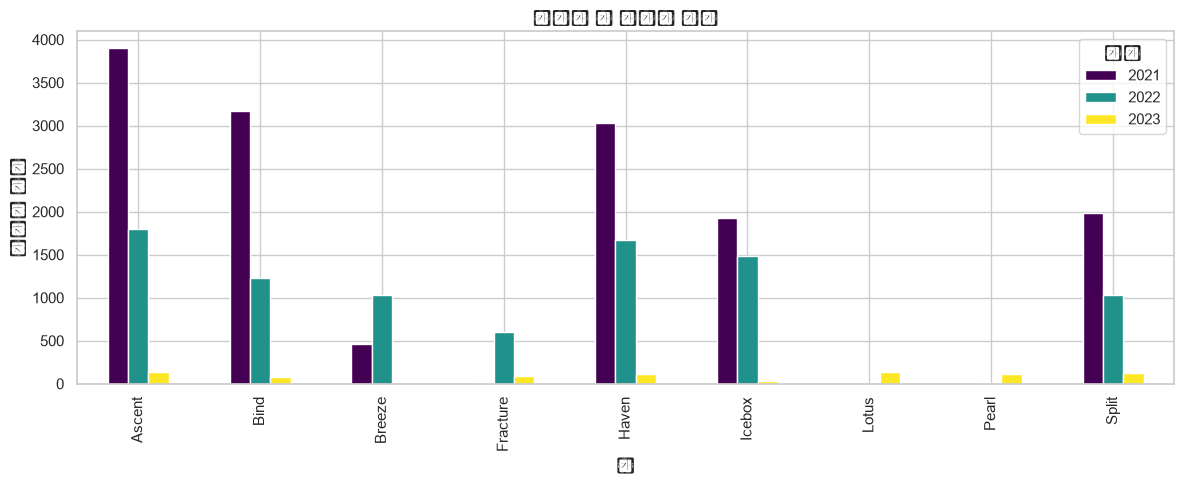

In [19]:
# 연도별 맵 픽 추이
fig, ax = plt.subplots(figsize=(12, 5))
map_year.T.plot(kind="bar", ax=ax, colormap="viridis")
ax.set_title("연도별 맵 플레이 횟수")
ax.set_xlabel("맵"); ax.set_ylabel("플레이 횟수")
ax.legend(title="연도")
plt.tight_layout()
plt.show()

### 💡 인사이트
- 2021: Ascent / Bind / Icebox 중심
- 2022: **Pearl 추가**, Breeze 증가
- 2023: **Lotus 추가**, Fracture 유지 → 맵 풀이 지속적으로 갱신됨

In [20]:
# 공격/수비 사이드 승률 (맵별 평균)
ms_map = mst[mst["Map"] != "All Maps"].copy()
side = ms_map.groupby("Map")[["Attacker Side Win Percentage", "Defender Side Win Percentage"]].mean()
side = side.sort_values("Attacker Side Win Percentage")
side

,Attacker Side Win Percentage,Defender Side Win Percentage
Map,,
Ascent,47.305132,52.718909
Split,47.815805,52.206774
Pearl,48.931034,51.149425
Bind,49.595681,50.433953
Fracture,51.012821,49.016484
Breeze,51.141268,48.892102
Haven,51.191866,48.837321
Icebox,51.586106,48.444250
Lotus,54.852632,45.189474


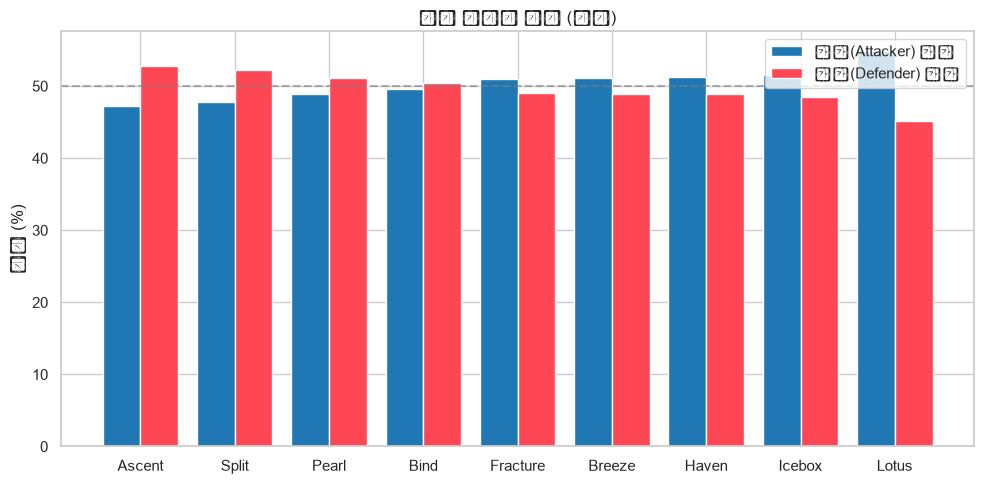

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(side))
ax.bar(x - 0.2, side["Attacker Side Win Percentage"], 0.4, label="공격(Attacker) 승률", color="#1f77b4")
ax.bar(x + 0.2, side["Defender Side Win Percentage"], 0.4, label="수비(Defender) 승률", color="#FF4655")
ax.axhline(50, color="gray", linestyle="--", alpha=0.6)
ax.set_xticks(x); ax.set_xticklabels(side.index)
ax.set_title("맵별 사이드 승률 (평균)")
ax.set_ylabel("승률 (%)"); ax.legend()
plt.tight_layout()
plt.show()

### 💡 인사이트
- 대부분 맵은 수비측 승률이 공격측보다 높은 **수비 친화적** 밸런스 (스파이크 설치보다 지키기가 유리)
- 맵별 편차가 크지 않아 대체로 밸런스 좋음

## 7. 경기 분석

### 7-1. 매치 스코어 분포

In [22]:
# 매치 결과 (scores.csv): Team A/B 스코어 = 세트(맵) 승패
mres = sc.dropna(subset=["Team A Score", "Team B Score"]).copy()
mres["Scoreline"] = mres["Team A Score"].astype(int).astype(str) + ":" + mres["Team B Score"].astype(int).astype(str)
score_dist = mres["Scoreline"].value_counts().head(10)
print("가장 흔한 매치 결과 (세트 스코어):")
score_dist

가장 흔한 매치 결과 (세트 스코어):


Scoreline
2:0     4201
0:2     2473
2:1     1504
1:2     1209
13:5      93
13:4      86
13:6      83
13:9      81
6:13      80
13:7      77
Name: count, dtype: int64

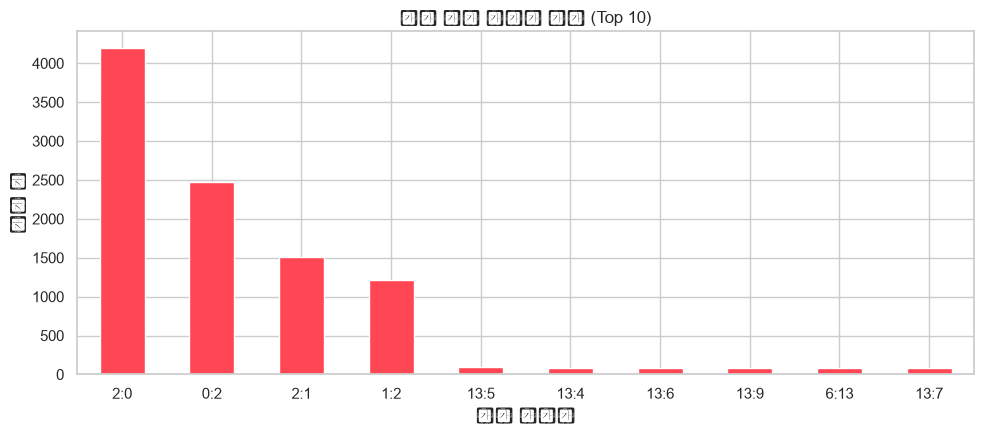

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
score_dist.plot(kind="bar", ax=ax, color="#FF4655")
ax.set_title("매치 세트 스코어 분포 (Top 10)")
ax.set_xlabel("세트 스코어"); ax.set_ylabel("매치 수")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 7-2. 맵 지속시간 분석

In [24]:
# Duration "MM:SS" 또는 "H:MM:SS" 파싱
def parse_duration(s):
    s = str(s)
    try:
        parts = s.split(":")
        if len(parts) == 3:
            return int(parts[0])*3600 + int(parts[1])*60 + int(parts[2])
        return int(parts[0])*60 + int(parts[1])
    except Exception:
        return np.nan

msc = msc.copy()
msc["DurationSec"] = msc["Duration"].apply(parse_duration)
msc["DurationMin"] = msc["DurationSec"] / 60
dur = msc.dropna(subset=["DurationMin"])
dur = dur[dur["DurationMin"] < 120]
print(f"유효 맵 경기 수: {len(dur):,}")
print(dur["DurationMin"].describe())

유효 맵 경기 수: 24,019
count    24019.000000
mean        40.502764
std         10.801458
min          6.916667
25%         32.766667
50%         39.700000
75%         46.833333
max        116.983333
Name: DurationMin, dtype: float64


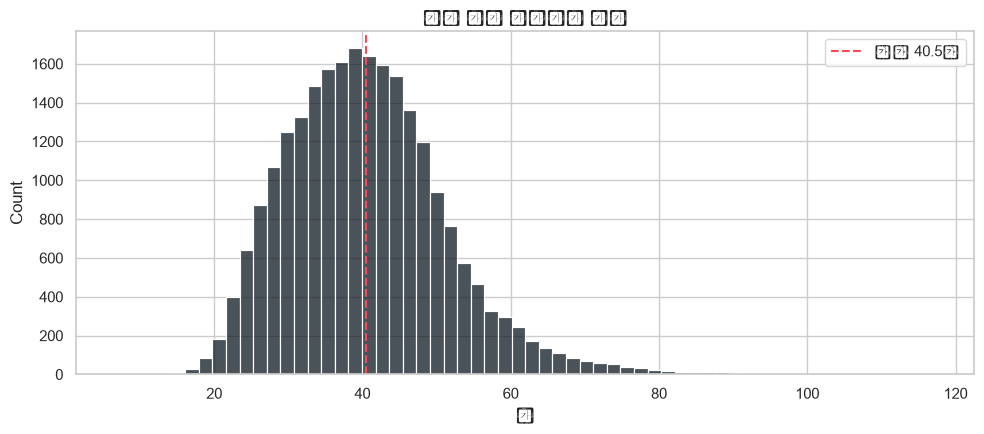

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(dur["DurationMin"], bins=60, ax=ax, color="#0F1923")
ax.set_title("맵별 경기 지속시간 분포")
ax.set_xlabel("분"); ax.axvline(dur["DurationMin"].mean(), color="#FF4655", linestyle="--", label=f"평균 {dur['DurationMin'].mean():.1f}분")
ax.legend()
plt.tight_layout()
plt.show()

### 💡 인사이트
- 한 맵당 평균 약 45~55분. 13라운드 선승제(오버타임 시 연장) 구조를 반영.

In [26]:
# 오버타임 여부 (13:13 → 오버타임 확률): 맵 스코어 확인
msc["A_win"] = msc["Team A Score"] > msc["Team B Score"]
ot = msc[(msc["Team A Score"] >= 13) & (msc["Team B Score"] >= 13)]
print(f"오버타임(양팀 13점 이상) 맵 수: {len(ot):,} / 총 맵 {len(msc):,} ({len(ot)/len(msc)*100:.1f}%)")

오버타임(양팀 13점 이상) 맵 수: 1,058 / 총 맵 24,217 (4.4%)


### 7-3. 라운드 승리 방식 (win_loss_methods)

In [27]:
# 각 팀 관점에서 "내가 이긴 방식" 컬럼만 사용
win_methods = ["Elimination", "Detonated", "Defused", "Time Expiry (No Plant)"]
wlm_win = wlm.groupby("year")[win_methods].sum()
total_wins = wlm_win.sum(axis=1)
wlm_ratio = wlm_win.div(total_wins, axis=0) * 100
wlm_ratio["총 승리 라운드"] = total_wins
wlm_ratio

,Elimination,Detonated,Defused,Time Expiry (No Plant),총 승리 라운드
year,,,,,
2021,71.461655,6.491345,19.992694,2.054306,290171
2022,72.003563,6.900699,18.762284,2.333454,179605
2023,64.582981,11.037901,21.304274,3.074844,17757


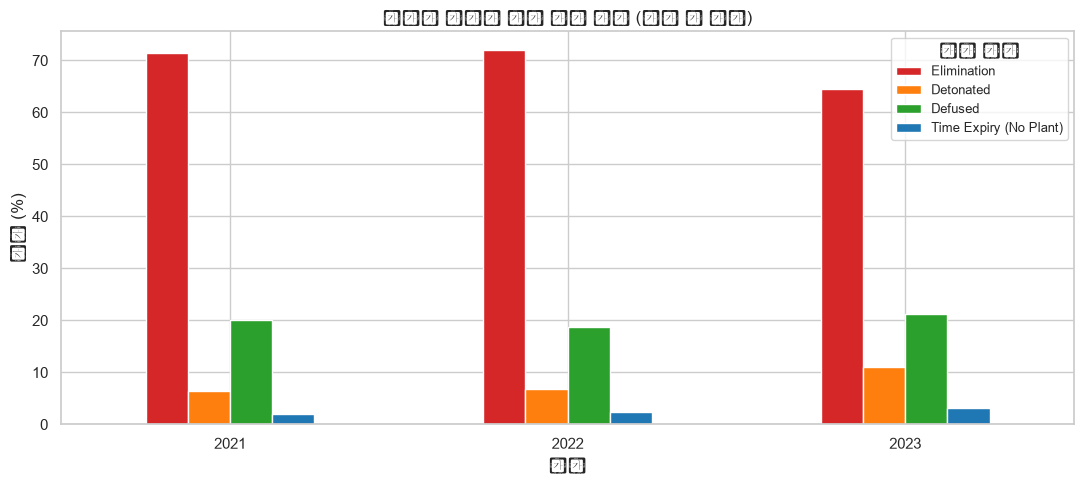

In [28]:
fig, ax = plt.subplots(figsize=(11, 5))
wlm_ratio[["Elimination", "Detonated", "Defused", "Time Expiry (No Plant)"]].plot(kind="bar", ax=ax, color=["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"])
ax.set_title("연도별 라운드 승리 방식 비율 (승리 팀 관점)")
ax.set_xlabel("연도"); ax.set_ylabel("비율 (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.legend(title="승리 방식", fontsize=9)
plt.tight_layout()
plt.show()

### 💡 인사이트
- 전체 라운드의 대부분은 **전멸(Elimination)**로 끝납니다.
- 폭탄 폭발(**Detonated**)로 이기는 비율은 낮고, **해체(Defused)**로 이기는 비율이 상대적으로 높은데,
  이는 수비 측이 유리한 발로란트의 특성(설치 전 전멸 vs 해체 시도)을 반영합니다.

### 7-4. 클러치 & 멀티킬 분석

In [29]:
# 클러치 지표 정리 (kills_stats)
ks2 = ks.dropna(subset=["Player"]).copy()
for c in ["2k", "3k", "4k", "5k", "1v1", "1v2", "1v3", "1v4", "1v5"]:
    ks2[c] = pd.to_numeric(ks2[c], errors="coerce")

clutch_cols = ["1v1", "1v2", "1v3", "1v4", "1v5"]
ks2["Clutches"] = ks2[clutch_cols].fillna(0).sum(axis=1)
ks2["MultiKills"] = ks2[["2k", "3k", "4k", "5k"]].fillna(0).sum(axis=1)

clutch_sum = ks2.groupby("Player")[clutch_cols + ["Clutches"]].sum().sort_values("Clutches", ascending=False)
clutch_sum.head(10)

,1v1,1v2,1v3,1v4,1v5,Clutches
Player,,,,,,
Shao,184.0,86.0,24.0,2.0,0.0,296.0
mindfreak,154.0,80.0,12.0,2.0,2.0,250.0
crashies,140.0,74.0,20.0,2.0,0.0,236.0
Benkai,124.0,61.0,18.0,6.0,0.0,209.0
AvovA,108.0,64.0,24.0,4.0,2.0,202.0
SUYGETSU,126.0,58.0,12.0,4.0,0.0,200.0
C0M,114.0,68.0,18.0,0.0,0.0,200.0
BORKUM,110.0,70.0,16.0,2.0,0.0,198.0
nukkye,92.0,70.0,30.0,2.0,2.0,196.0


In [30]:
# 멀티킬 합계 TOP
mk_sum = ks2.groupby("Player")[["2k", "3k", "4k", "5k", "MultiKills"]].sum().sort_values("MultiKills", ascending=False)
mk_sum.head(10)

,2k,3k,4k,5k,MultiKills
Player,,,,,
f0rsakeN,1801.0,657.0,173.0,39.0,2670.0
Derke,1542.0,630.0,152.0,24.0,2348.0
d4v41,1511.0,526.0,98.0,14.0,2149.0
ScreaM,1397.0,507.0,128.0,10.0,2042.0
Victor,1438.0,476.0,114.0,10.0,2038.0
aspas,1410.0,495.0,110.0,16.0,2031.0
Jinggg,1314.0,523.0,116.0,14.0,1967.0
yay,1289.0,513.0,139.0,16.0,1957.0
Jamppi,1363.0,424.0,108.0,18.0,1913.0


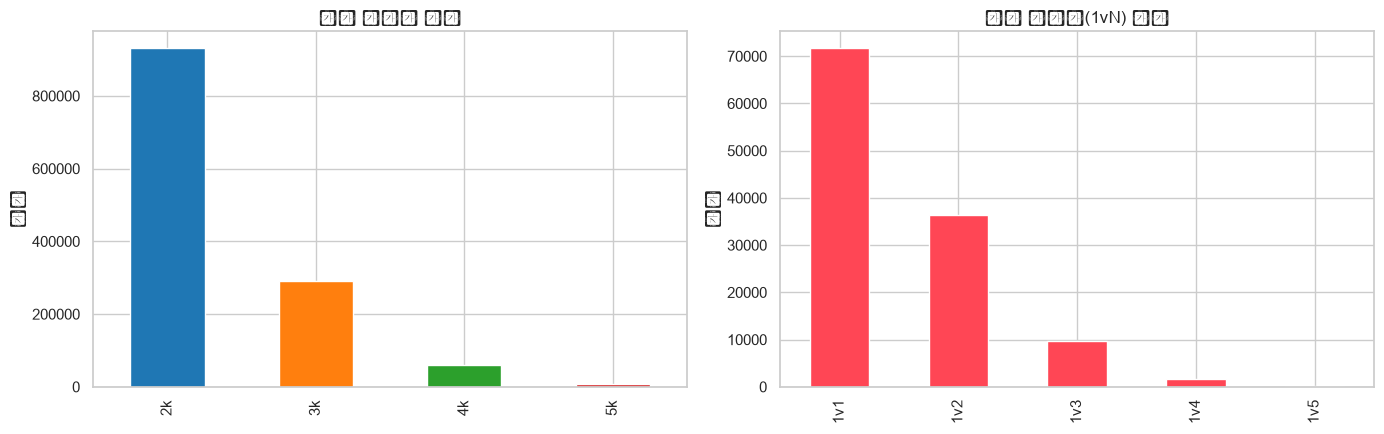

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# 멀티킬 구성 비율
mk_total = ks2[["2k", "3k", "4k", "5k"]].fillna(0).sum()
mk_total.plot(kind="bar", ax=axes[0], color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"])
axes[0].set_title("전체 멀티킬 구성")
axes[0].set_ylabel("건수")
# 클러치 1vN 구성
cl_total = ks2[["1v1", "1v2", "1v3", "1v4", "1v5"]].fillna(0).sum()
cl_total.plot(kind="bar", ax=axes[1], color="#FF4655")
axes[1].set_title("전체 클러치(1vN) 구성")
axes[1].set_ylabel("건수")
plt.tight_layout()
plt.show()

### 💡 인사이트
- **4k/5k**는 드물지만 경기 최고의 하이라이트로, 랭킹 상위권에는 듀얼리스트(요루/레이즈) 플레이어가 많음.
- **1v1 > 1v2 > 1v3 ...** 로 확률적으로 감소.

In [32]:
# 최다 1v5 클러치 플레이어
ks2[ks2["1v5"].fillna(0) > 0].groupby("Player")["1v5"].sum().sort_values(ascending=False).head(8)

Player
RAINMAKER    4.0
bang         4.0
cauanzin     4.0
Brofeld      3.0
AcMe         2.0
Azza         2.0
B3ar         2.0
Babyblue     2.0
Name: 1v5, dtype: float64

### 7-5. 경제(에코) 라운드 분석

In [33]:
# eco_stats: 타입별 (Pistol / Eco / $, $$, $$$)
# Initiated = 해당 유형 라운드 수, Won = 이긴 수. (Pistol은 Initiated가 비어 있어 제외)
eco2 = eco.dropna(subset=["Initiated"]).copy()
eco2["WinRate"] = eco2["Won"] / eco2["Initiated"] * 100
eco_type = eco2.groupby("Type")["WinRate"].mean().sort_values()
eco_type

Type
$ (won)      19.584677
Eco (won)    42.536628
$$ (won)     53.156547
$$$ (won)    54.429214
Name: WinRate, dtype: float64

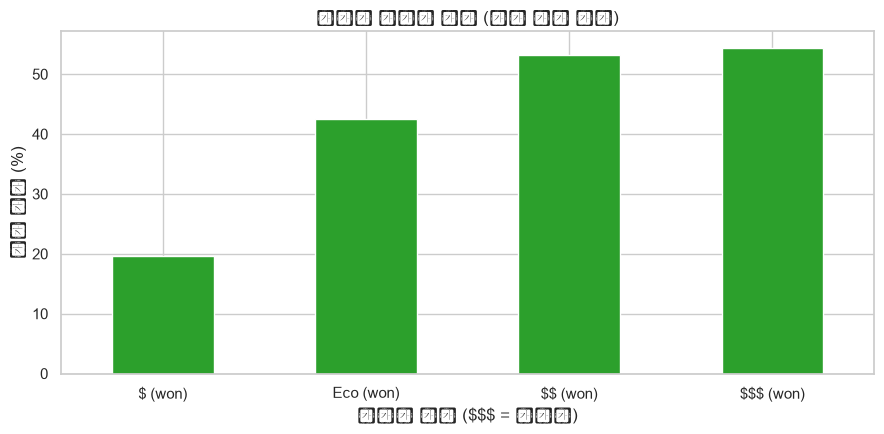

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.5))
eco_type.plot(kind="bar", ax=ax, color="#2ca02c")
ax.set_title("라운드 유형별 승률 (에코 구매 단계)")
ax.set_xlabel("라운드 유형 (\\$\\$\\$ = 풀바이)")
ax.set_ylabel("평균 승률 (%)")
# 라벨의 $ 를 mathtext 해석 방지 (단일 백슬래시로 escape)
new_labels = [t.get_text().replace("$", "\\" + "$") for t in ax.get_xticklabels()]
ax.set_xticklabels(new_labels, rotation=0)
plt.tight_layout()
plt.show()

### 💡 인사이트
- 무기 구매가 풍부한(더 많은 $) 라운드일수록 승률이 높습니다.
- **에코/포스바이(적은 예산) 라운드 승률이 낮아**, 자원 관리와 에코 라운드 클러치가 중요합니다.
- 피스톨 라운드는 별도(Initiated 집계 없음)로, 데이터셋에서는 승리 여부만 기록됩니다.

In [35]:
# 연도별 유형별 승률 변화
eco_type_year = eco2.groupby(["year", "Type"])["WinRate"].mean().unstack()
eco_type_year

Type,$ (won),$$ (won),$$$ (won),Eco (won)
year,,,,
2021,18.263419,53.329581,54.512212,42.735722
2022,20.650486,52.983737,54.403404,42.375122
2023,22.743262,53.151695,53.761796,42.096372


## 8. 종합 인사이트

### 핵심 요약

1. **데이터 규모**: 2021~2023 동안 **약 1.6만 명의 선수**가 약 1만 개 이상의 경기에 참가 (2021·2022 오픈 예선 포함).
2. **대회 구조 변화**: 2021년 지역별 예선 체제 → 2023년 국제 리그(연간 리그) 체제로 개편되어 **경기 수 급감**.
3. **선수 지표**: Rating은 1.0이 평균, 1.3+ 는 엘리트. HS% 평균 약 22%. K/D 1.0 기준.
4. **메타 변화**: 2021 Jett·Sova·Viper 원맨 메타 → 2023 신규 에이전트(Fade, Gekko 등) 등장과 밸런스 패치 반영.
5. **맵 밸런스**: 대부분 맵 수비 우세, 맵 풀은 2022년(펄), 2023년(로터스) 추가로 지속 갱신.
6. **경기 특징**: 한 맵 평균 45~55분, 라운드는 대부분 전멸로 종료, 공격보다 수비 승률 우세.
7. **경제**: 풀바이 라운드 승률이 에코 라운드보다 약 10~20%p 높음 → 자원 관리의 중요성.

### 참고사항 & 한계

- 데이터에 따라 일부 셀(예: 맵·에이전트 이름)에 소문자/오탈자 혼재.
- 2021·2022는 오픈 예선 데이터 포함으로 팀 수가 매우 많음 → 상위권 비교는 필터(최소 라운드) 필요.
- `Match Name` 기준으로 매치를 식별했으며, 같은 이름의 리매치가 있을 수 있음.

In [36]:
print("분석 완료 🎉")

분석 완료 🎉
